# ThermoLab
## The mathematics of cooling

Explore how a hot object cools, or a cold object warms, towards a constant room
temperature. Compare the exact solution with **Euler** and **Runge–Kutta (RK4)**.

This notebook contains all its calculation code. In Google Colab, choose a standard
CPU runtime and **Runtime → Run all**. No website server, GPU, account registration,
API key or Drive mount is needed. Use the controls near the end to create an experiment.

The default illustrative cup starts at **85°C** in a **22°C** room with
**k = 0.045 per minute**. Its exact temperature after 60 minutes is about **26.23°C**.
It reaches 45°C in about **22.39 minutes**. These are model outputs, not measurements.


## 1. Setup
The calculation engine uses Python's standard library. Matplotlib draws the graphs,
and ipywidgets supplies notebook controls. This cell installs a missing plotting or
widget package only when needed. A fresh installation needs internet access.

In [1]:
import importlib.util
import subprocess
import sys
missing = [name for name in ['matplotlib', 'ipywidgets'] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, FileLink, clear_output
import csv, io, json, html
from pathlib import Path
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.facecolor':'#fafbf6',
                     'axes.facecolor':'#fafbf6','axes.labelcolor':'#314d3e',
                     'text.color':'#314d3e','axes.edgecolor':'#cfd9c6'})
print('ThermoLab is ready. All time values below use minutes.')

ThermoLab is ready. All time values below use minutes.


## 2. The model

Newton's law of cooling describes a rate proportional to the temperature difference:

$$\frac{dT}{dt}=-k(T-T_a),\qquad T(0)=T_0.$$

Its exact solution is

$$T(t)=T_a+(T_0-T_a)e^{-kt}.$$

Here $T$ is the object's temperature in °C, $T_a$ is the constant room temperature,
$t$ is time in minutes and $k$ has units min$^{-1}$.

**Assumptions:** the object has one uniform temperature, the room stays constant,
and $k$ does not change. The model excludes evaporation, phase changes and detailed
heat flow. It is an educational example, not advice about food or drink safety.

The same equation models warming when the object starts below room temperature.
With $k=0$, the temperature stays unchanged. Room temperature is an asymptote when
the starting temperature differs from it and $k>0$.


In [2]:
"""Newton cooling and numerical approximations. Units: Celsius and minutes."""
from dataclasses import asdict, dataclass
import math

VERSION = 1
LIMIT = 100_000_000.0


class InputError(ValueError):
    pass


@dataclass(frozen=True)
class Parameters:
    initial: float = 85
    ambient: float = 22
    coefficient: float = 0.045
    duration: float = 60
    step: float = 1
    target: float = 45

    @classmethod
    def parse(cls, values):
        if not isinstance(values, dict):
            raise InputError('Experiment settings must be an object.')
        fields = cls.__dataclass_fields__
        if set(values) != set(fields):
            raise InputError('Provide exactly initial, ambient, coefficient, duration, step and target.')
        ranges = {'initial': (-50, 200), 'ambient': (-50, 200),
                  'coefficient': (0, 1), 'duration': (1, 240),
                  'step': (0.05, 30), 'target': (-50, 200)}
        cleaned = {}
        labels = {'initial': 'Starting temperature', 'ambient': 'Room temperature',
                  'coefficient': 'Cooling coefficient', 'duration': 'Duration',
                  'step': 'Calculation step', 'target': 'Chosen temperature'}
        for key, (lower, upper) in ranges.items():
            value = values[key]
            if isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value):
                raise InputError(f'{labels[key]} must be a finite number.')
            if not lower <= value <= upper:
                raise InputError(f'{labels[key]} must be between {lower} and {upper}.')
            cleaned[key] = float(value)
        if math.ceil(cleaned['duration'] / cleaned['step']) > 5000:
            raise InputError('Use a larger step to keep the experiment within 5,000 intervals.')
        return cls(**cleaned)


PRESETS = [
    {'id': 'warm-cup', 'name': 'The warm cup', 'description': 'A hot cup in a cooler room.',
     'tag': 'Start here', 'parameters': asdict(Parameters())},
    {'id': 'slow-cooling', 'name': 'A slower cool', 'description': 'Same start. A smaller cooling rate.',
     'tag': 'Compare rates', 'parameters': asdict(Parameters(coefficient=0.02, duration=120, step=2))},
    {'id': 'cold-object', 'name': 'From the cold', 'description': 'A cold object warms towards the room.',
     'tag': 'Reverse the story', 'parameters': asdict(Parameters(initial=5, ambient=24, coefficient=0.055, duration=60, target=20))},
    {'id': 'large-steps', 'name': 'The big-step test', 'description': 'See why the calculation step matters.',
     'tag': 'Numerical experiment', 'parameters': asdict(Parameters(coefficient=0.07, duration=90, step=20))},
]


def exact(p, time):
    return p.ambient + (p.initial - p.ambient) * math.exp(-p.coefficient * time)


def target_time(p):
    if p.target == p.initial:
        return {'status': 'at_start', 'minutes': 0.0, 'message': 'The object starts at the chosen temperature.'}
    if p.initial == p.ambient or p.coefficient == 0:
        return {'status': 'unreachable', 'minutes': None, 'message': 'The temperature stays constant in this experiment.'}
    if p.target == p.ambient:
        return {'status': 'asymptotic', 'minutes': None,
                'message': 'The model approaches room temperature without reaching it at a finite time.'}
    ratio = (p.target - p.ambient) / (p.initial - p.ambient)
    if not 0 < ratio < 1:
        return {'status': 'unreachable', 'minutes': None,
                'message': 'Choose a temperature strictly between the starting and room temperatures.'}
    time = -math.log(ratio) / p.coefficient
    return {'status': 'within_run' if time <= p.duration else 'after_run', 'minutes': time,
            'message': 'Reached within this experiment.' if time <= p.duration else 'Reached after the displayed duration.'}


def stability(factor, q, method):
    if q == 0:
        return 'constant'
    if abs(factor) > 1 + 1e-12:
        return 'unstable'
    if abs(abs(factor) - 1) <= 1e-12:
        return 'neutral'
    if factor < 0:
        return 'oscillating'
    if factor == 0:
        return 'one_step_equilibrium'
    return 'decaying'


def simulate(values):
    p = Parameters.parse(values)
    count = math.ceil(math.nextafter(p.duration / p.step, -math.inf))
    euler = rk4 = p.initial
    truncation = {'euler': None, 'rk4': None}
    samples = []
    first_step = None
    for index in range(count + 1):
        time = p.duration if index == count else index * p.step
        reference = exact(p, time)
        samples.append({'time': time, 'exact': reference, 'euler': euler, 'rk4': rk4,
                        'euler_error': abs(euler-reference) if euler is not None else None,
                        'rk4_error': abs(rk4-reference) if rk4 is not None else None})
        if index == count:
            break
        next_time = p.duration if index+1 == count else (index+1)*p.step
        h = next_time-time
        if euler is not None:
            euler = euler + h * (-p.coefficient * (euler-p.ambient))
        if rk4 is not None:
            f = lambda temperature: -p.coefficient * (temperature-p.ambient)
            a = f(rk4)
            b = f(rk4+h*a/2)
            c = f(rk4+h*b/2)
            d = f(rk4+h*c)
            rk4 = rk4 + h*(a+2*b+2*c+d)/6
            if first_step is None:
                first_step = {'h': h, 'slope': a, 'k1': a, 'k2': b, 'k3': c, 'k4': d,
                              'euler_next': euler, 'rk4_next': rk4, 'exact_next': exact(p, next_time)}
        if euler is not None and (not math.isfinite(euler) or abs(euler) > LIMIT):
            euler = None
            truncation['euler'] = next_time
        if rk4 is not None and (not math.isfinite(rk4) or abs(rk4) > LIMIT):
            rk4 = None
            truncation['rk4'] = next_time
    q = p.coefficient * min(p.step, p.duration)
    factor_euler = 1-q
    factor_rk4 = 1-q+q*q/2-q**3/6+q**4/24
    warnings = []
    methods = {}
    for name, factor in [('euler', factor_euler), ('rk4', factor_rk4)]:
        state = stability(factor, q, name)
        errors = [s[name+'_error'] for s in samples if s[name+'_error'] is not None]
        methods[name] = {'amplification': factor, 'stability': state,
                         'max_abs_error': None if truncation[name] is not None else max(errors),
                         'final_abs_error': samples[-1][name+'_error'], 'truncated_at': truncation[name]}
        label = 'Euler' if name == 'euler' else 'RK4'
        if state in ('oscillating', 'neutral', 'unstable', 'one_step_equilibrium'):
            descriptions = {'oscillating': 'crosses room temperature because the step is too large for a monotone estimate',
                            'neutral': 'does not reduce the temperature difference with this step',
                            'unstable': 'amplifies numerical errors with this step',
                            'one_step_equilibrium': 'jumps to room temperature in one step'}
            warnings.append(f'{label} {descriptions[state]}. This is a numerical effect, not the physical reference motion.')
        if truncation[name] is not None:
            warnings.append(f'{label} exceeds the {LIMIT:g} °C calculation limit at {truncation[name]:g} min. Later values are unavailable.')
    reference = [{'time': p.duration*i/400, 'exact': exact(p, p.duration*i/400)} for i in range(401)]
    return {'schema_version': VERSION, 'parameters': asdict(p), 'samples': samples, 'reference': reference,
            'summary': {'direction': 'steady' if p.initial == p.ambient or p.coefficient == 0 else ('cooling' if p.initial > p.ambient else 'warming'),
                        'half_life': math.log(2)/p.coefficient if p.coefficient else None,
                        'final_temperature': samples[-1]['exact'], 'target': target_time(p),
                        'steps': count, 'methods': methods, 'first_step': first_step},
            'warnings': warnings}


## 3. A worked experiment

Euler uses the current rate for one step:

$$T_{n+1}=T_n-hk(T_n-T_a).$$

RK4 evaluates four rates within the same step and combines them. Both methods use
the same time grid for comparison with the exact solution. The final step shortens
when necessary so the experiment ends at the requested time.

The exact graph uses a separate dense grid, so a large numerical step does not
turn the physical reference into a few straight segments.


Start: 85.0°C | room: 22.0°C | k: 0.045 per minute
First Euler step: 85.0 + 1.0 × (-2.8350) = 82.16500°C
First RK4 step: 82.22784°C | exact: 82.22784°C
After 60 min: 26.23395°C
Time to 45°C: 22.39201 min
Time to halve the temperature difference: 15.40327 min


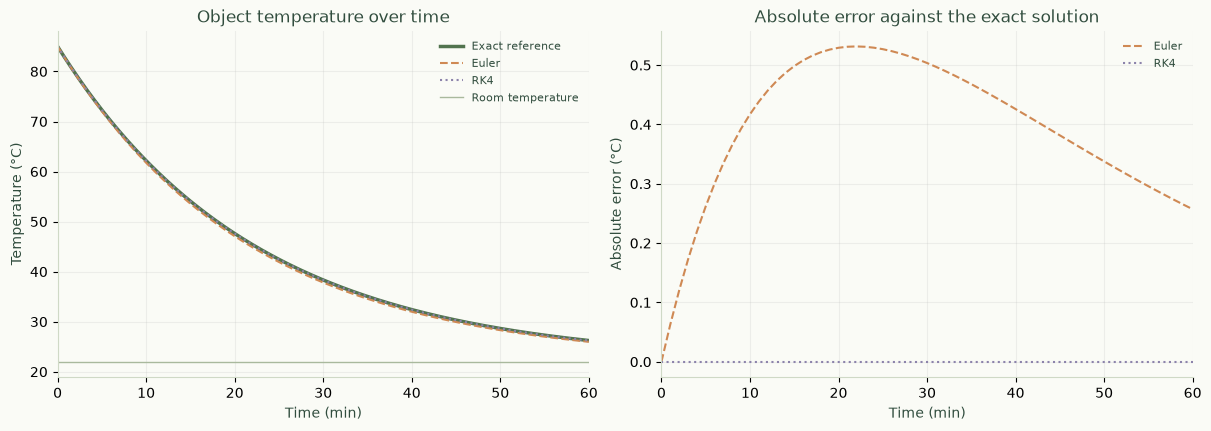

In [3]:
def plot_experiment(result):
    p=result['parameters']; rows=result['samples']; reference=result['reference']
    fig,axes=plt.subplots(1,2,figsize=(12,4.2),layout='constrained')
    axes[0].plot([r['time'] for r in reference],[r['exact'] for r in reference],
                 color='#51734e',linewidth=2.5,label='Exact reference')
    for key,color,style in [('euler','#cf8954','--'),('rk4','#8c83ab',':')]:
        axes[0].plot([r['time'] for r in rows],[r[key] for r in rows],
                     color=color,linestyle=style,label='Euler' if key=='euler' else 'RK4')
        axes[1].plot([r['time'] for r in rows],[r[key+'_error'] for r in rows],
                     color=color,linestyle=style,label='Euler' if key=='euler' else 'RK4')
    axes[0].axhline(p['ambient'],color='#a9b99d',linewidth=1,label='Room temperature')
    axes[0].set(title='Object temperature over time',xlabel='Time (min)',ylabel='Temperature (°C)')
    axes[1].set(title='Absolute error against the exact solution',xlabel='Time (min)',ylabel='Absolute error (°C)')
    for axis in axes:
        axis.grid(alpha=.18);axis.legend(frameon=False,fontsize=8);axis.set_xlim(0,p['duration'])
    if result['warnings']:
        print('Numerical note: '+' '.join(result['warnings']))
    display(fig);plt.close(fig)
    return fig

default_result=simulate(asdict(Parameters()))
p=default_result['parameters'];s=default_result['summary'];f=s['first_step']
print(f"Start: {p['initial']}°C | room: {p['ambient']}°C | k: {p['coefficient']} per minute")
print(f"First Euler step: {p['initial']} + {f['h']} × ({f['slope']:.4f}) = {f['euler_next']:.5f}°C")
print(f"First RK4 step: {f['rk4_next']:.5f}°C | exact: {f['exact_next']:.5f}°C")
print(f"After 60 min: {s['final_temperature']:.5f}°C")
print(f"Time to 45°C: {s['target']['minutes']:.5f} min")
print(f"Time to halve the temperature difference: {s['half_life']:.5f} min")
plot_experiment(default_result);

## 4. What a larger step changes

The big-step preset deliberately makes Euler cross room temperature. That oscillation
belongs to the approximation, not the physical model. Compare it with the smooth
reference. Reducing the step should bring a suitable approximation closer to the reference.

For Euler, the difference from room temperature is multiplied by $1-kh$ per full
step. Values between 0 and 1 decay without crossing. A negative factor can create
alternation. A factor with absolute value greater than 1 produces growth.

If an approximation exceeds the documented 100 million °C numerical limit, the
engine marks subsequent values unavailable instead of silently clamping them.


Numerical note: Euler crosses room temperature because the step is too large for a monotone estimate. This is a numerical effect, not the physical reference motion.


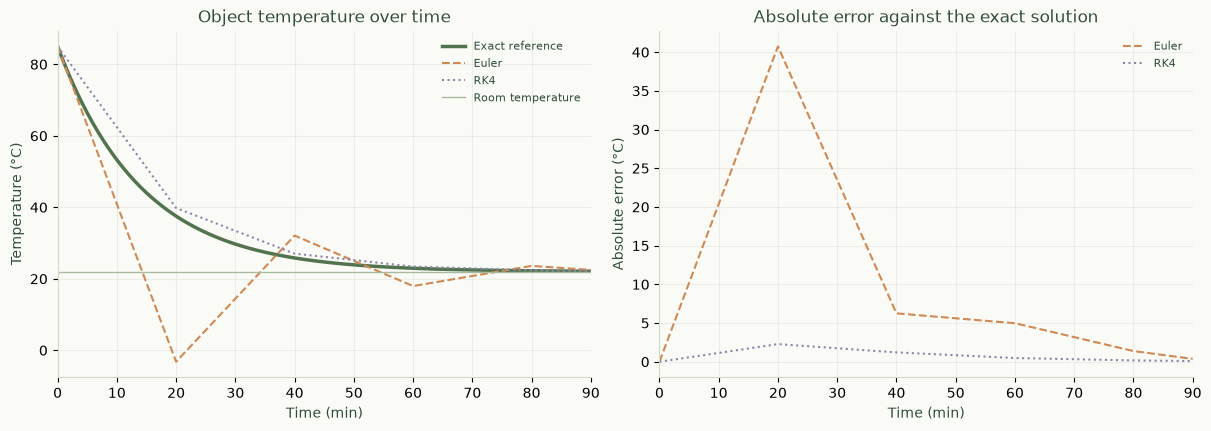

Euler state: oscillating
Model checks passed: target time, numerical comparison and unreachable targets.


In [4]:
big_step=simulate(PRESETS[3]['parameters'])
plot_experiment(big_step);
print('Euler state:',big_step['summary']['methods']['euler']['stability'])
assert big_step['summary']['methods']['euler']['stability']=='oscillating'
assert default_result['summary']['methods']['rk4']['max_abs_error'] < default_result['summary']['methods']['euler']['max_abs_error']
assert abs(exact(Parameters(),default_result['summary']['target']['minutes'])-45)<1e-10
assert target_time(Parameters(target=22))['status']=='asymptotic'
assert target_time(Parameters(target=100))['status']=='unreachable'
print('Model checks passed: target time, numerical comparison and unreachable targets.')

## 5. Create your own experiment

Choose a preset, change a field and press **Calculate experiment**. The displayed
result and exports always describe the last calculated settings, not unsubmitted
edits. Change one value at a time to understand its effect.

- **Cooling coefficient:** a larger value approaches room temperature faster.
- **Calculation step:** the gap between numerical calculations, in minutes.
- **Chosen temperature:** a target for the exact crossing-time calculation.
- **Half-life:** time for the difference from room temperature to halve. This does
  not mean halving a Celsius temperature.


In [5]:
controls={}
labels={'initial':'Start (°C)','ambient':'Room (°C)','coefficient':'k (per min)',
        'duration':'Duration (min)','step':'Step (min)','target':'Target (°C)'}
for key in Parameters.__dataclass_fields__:
    controls[key]=widgets.FloatText(value=asdict(Parameters())[key],description=labels[key],
        style={'description_width':'110px'},layout=widgets.Layout(width='285px'))
preset_picker=widgets.Dropdown(options=[(p['name'],p['id']) for p in PRESETS],
                               description='Experiment:',layout=widgets.Layout(width='360px'))
calculate_button=widgets.Button(description='Calculate experiment',button_style='success',layout=widgets.Layout(width='190px'))
csv_button=widgets.Button(description='Download CSV')
settings_button=widgets.Button(description='Download settings')
result_output=widgets.Output()
export_output=widgets.Output()
last_result={'value':default_result}

def choose_preset(change):
    p=next(p for p in PRESETS if p['id']==change['new'])
    for key,value in p['parameters'].items():controls[key].value=value

def calculate_clicked(_=None):
    with result_output:
        clear_output(wait=True)
        try:
            result=simulate({key:widget.value for key,widget in controls.items()})
        except InputError as error:
            print('Please check your inputs:',error)
            print('Downloads still refer to the last successful calculation.')
            return
        last_result['value']=result
        p=result['parameters'];s=result['summary'];target=s['target']
        print(f"Calculated: start {p['initial']:g}°C, room {p['ambient']:g}°C, k={p['coefficient']:g}, step={p['step']:g} min")
        print(f"Final reference temperature: {s['final_temperature']:.4f}°C")
        if target['minutes'] is not None:print(f"Chosen temperature reached at {target['minutes']:.4f} min. {target['message']}")
        else:print(target['message'])
        plot_experiment(result)
        print('First six numerical samples:')
        print(f"{'min':>9} {'exact °C':>13} {'Euler °C':>13} {'RK4 °C':>13}")
        for row in result['samples'][:6]:
            values=[f"{row[key]:.5f}" if row[key] is not None else 'unavailable' for key in ['exact','euler','rk4']]
            print(f"{row['time']:9.3f} {values[0]:>13} {values[1]:>13} {values[2]:>13}")

def save_export(kind):
    result=last_result['value'];folder=Path('thermolab_exports');folder.mkdir(exist_ok=True)
    if kind=='csv':
        target=folder/'ThermoLab-results.csv'
        with target.open('w',newline='',encoding='utf-8') as stream:
            writer=csv.writer(stream)
            writer.writerow(['time_min','exact_C','euler_C','rk4_C','abs_error_euler_C','abs_error_rk4_C',
                             'initial_C','ambient_C','coefficient_per_min','duration_min','calculation_step_min','target_C'])
            for row in result['samples']:
                writer.writerow([row[key] for key in ['time','exact','euler','rk4','euler_error','rk4_error']]+
                                [result['parameters'][key] for key in Parameters.__dataclass_fields__])
    else:
        target=folder/'ThermoLab-settings.json'
        target.write_text(json.dumps({'application':'ThermoLab','schema_version':1,'parameters':result['parameters']},indent=2),encoding='utf-8')
    with export_output:
        clear_output(wait=True)
        try:
            from google.colab import files
        except ImportError:
            display(FileLink(str(target)))
        else:
            files.download(str(target))

preset_picker.observe(choose_preset,names='value')
calculate_button.on_click(calculate_clicked)
csv_button.on_click(lambda _:save_export('csv'))
settings_button.on_click(lambda _:save_export('json'))
display(widgets.VBox([preset_picker,
    widgets.HBox([widgets.VBox([controls['initial'],controls['coefficient'],controls['step']]),
                  widgets.VBox([controls['ambient'],controls['duration'],controls['target']])]),
    widgets.HBox([calculate_button,csv_button,settings_button]),result_output,export_output]))
calculate_clicked()

## 6. One question to investigate

Keep everything else fixed and halve $k$. What happens to the time needed to halve
the temperature difference? The calculation below checks the relationship with
the exact solution. Try the same comparison in the website.


In [6]:
original=Parameters()
slower=Parameters(coefficient=original.coefficient/2)
first=math.log(2)/original.coefficient
second=math.log(2)/slower.coefficient
print(f"Original half-life: {first:.4f} min")
print(f"Half the coefficient: {second:.4f} min")
assert math.isclose(second,2*first)
print('Halving the coefficient doubles the half-life of the difference.')

Original half-life: 15.4033 min
Half the coefficient: 30.8065 min
Halving the coefficient doubles the half-life of the difference.


## References and practical limits

- [OpenStax: Exponential and logarithmic models, including Newton cooling](https://openstax.org/books/algebra-and-trigonometry-2e/pages/6-7-exponential-and-logarithmic-models)
- [OpenStax: Basics of differential equations](https://openstax.org/books/calculus-volume-2/pages/4-1-basics-of-differential-equations)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)

Sources checked 17 November 2026. Colab resources and runtimes are temporary.
Download the notebook, results and settings before disconnecting. Widgets need a
connected Python runtime. Saved plots remain useful without an active runtime.
This notebook runs in the normal notebook interface and does not need a website
tunnel. The separate local ThermoLab website uses the same calculation engine.

The project demonstrates a first-order differential-equation model and numerical
approximations. It does not claim to cover every Computational Mathematics experiment.
